CAPITOLO 3 MODULO 5 PROGETTO 2 

Machine Learning
Progetto 2
Il dataset Linnerud presenta un problema di regressione Multi-Target (3 target
totali: Weight, Waist, Pulse).
Addestrare e confrontare alcuni modelli di regressione sul dataset, riducendo il
problema da Multi-Target a Single-Target tramite
1. PCA
2. selezione manuale di un singolo target

1 Data Exploration & Preprocessing
• Caricamento e Analisi del dataset e fornire un’analisi descrittiva iniziale
(i.e. df.describe())
• Standardization delle feature (X) per garantire che tutti gli attributi
abbiano media zero e deviazione standard unitaria

2 Target Engineering
Trasformare il problema Multi-Target in due distinti problemi Single-Target da
confrontare:
• PCA (Target Composto)
– Applicare la PCA alla matrice dei target standardizzata e mantenere
PC1
• Manuale (Target Selezionato)
– Selezionare il target Waist dalla matrice dei target standardizzata
come singolo target rappresentativo
1

3 Addestramento & Valutazione
Addestrare i tre modelli di regressione (Linear Regression, Ridge, Lasso) su
entrambi gli scenari di target ridotto con PCA e selezione manuale, utilizzando
il set di feature completo e standardizzato:
• Definire e inizializzare i tre modelli di regressione (Lineare, Ridge con
α = 1.0, Lasso con α = 0.1)
• Eseguire l’addestramento su tutto il dataset per entrambi gli scenari
• Valutare e memorizzare i risultati come Mean Squared Error e R2 Score
per ogni combinazione di modello e scenario
4 Analisi & Visualizzazione
• Applicare la PCA al set di feature standardizzato e mantenere le due
componenti principali PC1 e PC2 per la visualizzazione 2D
• Creare un grafico di dispersione in cui:
– L’asse X `e il PC1 delle Feature
– L’asse Y `e la PCA con n components=1
– Tracciare le tre rette di regressione (Lineare, Ridge, Lasso) ri-addestrate
sulla sola PC1 delle Feature, includendo il loro rispettivo R2 Score
finale nell’etichetta


1 Data Exploration & Preprocessing
• Caricamento e Analisi del dataset e fornire un’analisi descrittiva iniziale
(i.e. df.describe())
• Standardization delle feature (X) per garantire che tutti gli attributi
abbiano media zero e deviazione standard unitaria

In [4]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.datasets import load_linnerud
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, r2_score





In [5]:
data = load_linnerud()
X = pd.DataFrame(data.data, columns = data.feature_names)
y= pd.DataFrame(data.target, columns= data.target_names)

X.head()



,Chins,Situps,Jumps
0,5.0,162.0,60.0
1,2.0,110.0,60.0
2,12.0,101.0,101.0
3,12.0,105.0,37.0
4,13.0,155.0,58.0


In [6]:
y.head()


,Weight,Waist,Pulse
0,191.0,36.0,50.0
1,189.0,37.0,52.0
2,193.0,38.0,58.0
3,162.0,35.0,62.0
4,189.0,35.0,46.0


In [7]:
X.describe()


,Chins,Situps,Jumps
count,20.000000,20.000000,20.00000
mean,9.450000,145.550000,70.30000
std,5.286278,62.566575,51.27747
min,1.000000,50.000000,25.00000
25%,4.750000,101.000000,39.50000
50%,11.500000,122.500000,54.00000
75%,13.250000,210.000000,85.25000
max,17.000000,251.000000,250.00000


In [8]:
y.describe()

,Weight,Waist,Pulse
count,20.000000,20.000000,20.000000
mean,178.600000,35.400000,56.100000
std,24.690505,3.201973,7.210373
min,138.000000,31.000000,46.000000
25%,160.750000,33.000000,51.500000
50%,176.000000,35.000000,55.000000
75%,191.500000,37.000000,60.500000
max,247.000000,46.000000,74.000000


In [9]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

2 Target Engineering
Trasformare il problema Multi-Target in due distinti problemi Single-Target da
confrontare:
• PCA (Target Composto)
– Applicare la PCA alla matrice dei target standardizzata e mantenere
PC1
• Manuale (Target Selezionato)
– Selezionare il target Waist dalla matrice dei target standardizzata
come singolo target rappresentativo
1

In [10]:
y_scaled = scaler.fit_transform(y)

#scenario 1 

pca= PCA(n_components = 1, random_state = 42)
y_pca= pca.fit_transform(y_scaled)

for nome_target, peso in zip (y.columns, pca.components_[0]):
    print(f"Target: {nome_target} / Peso del target nella PC1: {peso:.4f}")

Target: Weight / Peso del target nella PC1: 0.6437
Target: Waist / Peso del target nella PC1: 0.6410
Target: Pulse / Peso del target nella PC1: -0.4181


In [11]:
#scenario 2 
y_waist = y_scaled[:,1]


3 Addestramento & Valutazione
Addestrare i tre modelli di regressione (Linear Regression, Ridge, Lasso) su
entrambi gli scenari di target ridotto con PCA e selezione manuale, utilizzando
il set di feature completo e standardizzato:
• Definire e inizializzare i tre modelli di regressione (Lineare, Ridge con
α = 1.0, Lasso con α = 0.1)
• Eseguire l’addestramento su tutto il dataset per entrambi gli scenari
• Valutare e memorizzare i risultati come Mean Squared Error e R2 Score
per ogni combinazione di modello e scenario

In [12]:
lin_reg = LinearRegression()

ridge_reg = Ridge(alpha=1)

lasso_reg = Lasso(alpha = 0.1)

#scenario 1 PC1

lin_reg.fit(X_scaled, y_pca)
y_lin = lin_reg.predict(X_scaled)
mse_lin = mean_squared_error(y_pca, y_lin)
r2_lin = r2_score(y_pca, y_lin)

ridge_reg.fit(X_scaled, y_pca)
y_ridge = ridge_reg.predict(X_scaled)
mse_ridge = mean_squared_error(y_pca, y_ridge)
r2_ridge = r2_score(y_pca, y_ridge)

lasso_reg.fit(X_scaled,y_pca)
y_lasso = lasso_reg.predict(X_scaled)
mse_lasso = mean_squared_error(y_pca, y_lasso)
r2_lasso = r2_score(y_pca, y_lasso)


#scenario 2

lin_reg.fit(X_scaled, y_waist)
y_lin2 = lin_reg.predict(X_scaled)
mse_lin2 = mean_squared_error(y_waist, y_lin2)
r2_lin2 = r2_score(y_waist, y_lin2)

ridge_reg.fit(X_scaled, y_waist)
y_ridge2 = ridge_reg.predict(X_scaled)
mse_ridge2 = mean_squared_error(y_waist, y_ridge2)
r2_ridge2 = r2_score(y_waist, y_ridge2)

lasso_reg.fit(X_scaled, y_waist)
y_lasso2 = lasso_reg.predict(X_scaled)
mse_lasso2 = mean_squared_error(y_waist, y_lasso2)
r2_lasso2 = r2_score(y_waist, y_lasso2)





4 Analisi & Visualizzazione
• Applicare la PCA al set di feature standardizzato e mantenere le due
componenti principali PC1 e PC2 per la visualizzazione 2D
• Creare un grafico di dispersione in cui:
– L’asse X `e il PC1 delle Feature
– L’asse Y `e la PCA con n components=1
– Tracciare le tre rette di regressione (Lineare, Ridge, Lasso) ri-addestrate
sulla sola PC1 delle Feature, includendo il loro rispettivo R2 Score
finale nell’etichetta

In [13]:
pca2 = PCA(n_components = 2, random_state=42)
X_pca = pca2.fit_transform(X_scaled)

lin_reg = LinearRegression()

ridge_reg = Ridge(alpha=1)

lasso_reg = Lasso(alpha = 0.1)

#riaddestrare solo i modelli solo sulla  PC1

lin_reg.fit(X_pca[:,0:1], y_pca)
y_lin3 = lin_reg.predict(X_pca[:,0:1])
mse_lin3 = mean_squared_error(y_pca, y_lin3)
r2_lin3 = r2_score(y_pca, y_lin3)

ridge_reg.fit(X_pca[:,0:1], y_pca)
y_ridge3 = ridge_reg.predict(X_pca[:,0:1])
mse_ridge3 = mean_squared_error(y_pca, y_ridge3)
r2_ridge3 = r2_score(y_pca, y_ridge3)

lasso_reg.fit(X_pca[:,0:1],y_pca)
y_lasso3 = lasso_reg.predict(X_pca[:,0:1])
mse_lasso3 = mean_squared_error(y_pca, y_lasso3)
r2_lasso3 = r2_score(y_pca, y_lasso3)


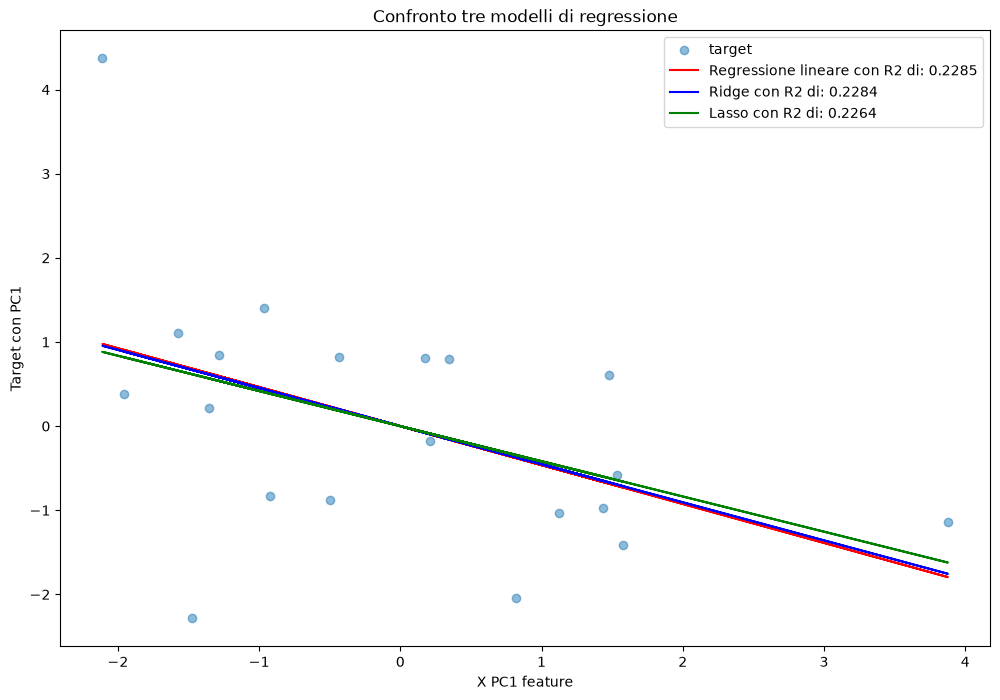

In [24]:
#CREAZIONE DEL GRAFICO  

plt.figure(figsize=(12,8))
plt.scatter(X_pca[:,0:1], y_pca, label = "target", alpha= 0.5)
plt.plot(X_pca[:,0:1], y_lin3, color = "red", label= (f"Regressione lineare con R2 di: {r2_lin3:.4f}"))
plt.plot(X_pca[:,0:1], y_ridge3, color = "blue", label = (f"Ridge con R2 di: {r2_ridge3:.4f}"))
plt.plot(X_pca[:,0:1], y_lasso3, color = "Green", label = (f"Lasso con R2 di: {r2_lasso3:.4f}"))
plt.xlabel("X PC1 feature")
plt.ylabel("Target con PC1")
plt.title("Confronto tre modelli di regressione")
plt.legend()
plt.show()





